# Session 1 — Introduction to AI, ML, and data

**Question:** What information can a system legitimately learn from?

Read each explanation before running its cell. Run from a fresh Python 3 kernel, top to bottom. No downloads or GPU are needed. Seeds are fixed. Companion: [lecture PDF](../PdfLectures/01_introduction_and_data.pdf). Try the [student application](../StudentApplications/01_introduction_and_data_student.ipynb) afterward.

## Problem statement

An online service receives requests to read or write data. A request is one job sent to the service; latency is the time it takes to finish. The service team wants a warning at arrival if a request will take more than 110 milliseconds (ms). At that moment the finishing time is still unknown. A warning is a prediction, not a measurement of the completed job.

**Given.** You are given code that generates 1,200 independent, fictional past requests. For each request, arrival-time information records the amount of data sent (payload, in MB), the number of jobs already waiting (queue), whether reusable data is in fast storage (cache: 1 for a hit, 0 for a miss), and the operation (endpoint: read or write). The completed request supplies its measured latency and therefore its label: 1 for more than 110 ms, otherwise 0. Some payload measurements are missing. The supplied split reserves 720 rows for learning, 240 for checking choices, and 240 for final assessment.

**Concrete example.** Illustration, not an extra dataset row: a request arrives with payload 4 MB, queue 3, cache 0, and endpoint read. These four values can inform a warning. If it later finishes in 125 ms, its recorded label is 1; if it finishes in 90 ms, its label is 0. The eventual time cannot be used to predict itself at arrival.

**Objective.** Before fitting a useful warning model, investigate what can be known at arrival, how missing and categorical inputs become numbers, and how an always-majority baseline behaves.

**Route and expected result.** Inspect the training table, prepare inputs using training statistics, audit leakage, and measure the baseline on validation. By the end, explain which information is legal and why baseline accuracy can hide missed slow requests. Test data remain unused.

**Your role in this worked notebook.** The code is complete. Read the predictions and questions, run the supplied cells in order, interpret their tables and figures, and attempt the closing exercise before reading its answer notes. The separate student application contains the implementation tasks.

## Before coding: specify the decision
A fixed rule such as `queue > 4` encodes a human choice. A learned model estimates parameters
from examples. Both require a precise task. Our input is an arrival-time request, our output
is an estimated violation probability, and our later action is whether to raise a warning.

**Predict first:** Could a final response code, total execution time, or request identifier
be a useful feature? Separate information available at arrival from information recorded later.
An identifier may also encourage memorization without a stable relationship to the target.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, log_loss, mean_squared_error, mean_absolute_error)
print('Python', sys.version.split()[0], '| scikit-learn', sklearn.__version__)
plt.rcParams.update({'figure.figsize': (6, 4), 'axes.grid': True, 'grid.alpha': 0.2})

Python 3.12.9 | scikit-learn 1.8.0


## Shared case study: warn before a request exceeds 110 ms
A row is an independent simulated service request. At arrival we know **payload** (MB),
**queue** length, **cache** hit (0/1), and **endpoint** (`read`/`write`). The target is
1 if the eventual latency exceeds 110 ms. Latency itself must never be an input.

The simulator combines linear effects, a queue/cache interaction, and noise with SD 9 ms.
Five percent of payload readings are missing independently. This is teaching data, not evidence
about a real service. We use the same seed and the same 720/240/240 row partitions in sessions
1, 3, 4 and 6. Random splitting is justified by the independent simulation; real repeated users
or future requests would need group or chronological splitting.

`fit` learns from training rows. `transform`, `predict`, and `predict_proba` reuse that state.
All preprocessing is inside each model's pipeline. Validation supports choices; the test is
opened only after those choices are frozen. Since these notebooks share a test partition,
repeated classroom comparisons are illustrations, not independent fresh confirmations.

In [2]:
# Identical data and row partitions in sessions 1, 3, 4 and 6.
rng = np.random.default_rng(17)
n = 1200
payload = rng.uniform(0.5, 10, n)  # MB, recorded before execution
queue = rng.poisson(3, n)
cache = rng.binomial(1, 0.4, n)
endpoint = rng.choice(['read', 'write'], n, p=[0.7, 0.3])
latency = (35 + 7*payload + 4*queue - 18*cache + 12*(endpoint == 'write')
           + 22*((queue > 4) & (cache == 0)) + rng.normal(0, 9, n))
X = pd.DataFrame({'payload': payload, 'queue': queue, 'cache': cache, 'endpoint': endpoint})
X.loc[rng.random(n) < 0.05, 'payload'] = np.nan  # sensor missingness after outcomes are generated
y = pd.Series((latency > 110).astype(int), name='budget_violation')
train_valid, test = train_test_split(np.arange(n), test_size=0.2, random_state=23, stratify=y)
train, valid = train_test_split(train_valid, test_size=0.25, random_state=23, stratify=y.iloc[train_valid])
assert not (set(train) & set(valid) or set(train) & set(test) or set(valid) & set(test))
assert len(train) + len(valid) + len(test) == n
Xtr, Xva, Xte = X.iloc[train], X.iloc[valid], X.iloc[test]
ytr, yva, yte = y.iloc[train], y.iloc[valid], y.iloc[test]
print('Rows:', len(train), len(valid), len(test), '| Training event rate:', round(ytr.mean(), 3))
def preprocessing():
    return ColumnTransformer([
        ('numeric', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()),
         ['payload', 'queue', 'cache']),
        ('category', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['endpoint'])
    ])
def classification_report_row(y_true, probability, threshold=0.5):
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, prediction, labels=[0, 1]).ravel()
    return {'accuracy': accuracy_score(y_true, prediction),
            'precision': precision_score(y_true, prediction, zero_division=0),
            'recall': recall_score(y_true, prediction, zero_division=0),
            'F1': f1_score(y_true, prediction, zero_division=0),
            'log_loss': log_loss(y_true, probability, labels=[0, 1]),
            'FP': fp, 'FN': fn, 'cost_per_row': (fp + 5*fn)/len(y_true)}

Rows: 720 240 240 | Training event rate: 0.147


## 1. Audit the training table
Look at units, types, missingness, and class balance before choosing a model. `head()` alone
cannot establish data quality. Only training rows are used for this exploratory report.

**Question:** Does a missing payload mean a payload of zero? Why would replacing all missing
values by zero change the meaning of the feature?

,payload,queue,cache,endpoint
95,1.996364,2,0,read
72,6.136135,2,0,write
1123,4.014792,2,1,read
259,6.850844,1,0,write
870,7.773248,1,0,read


,dtype,missing
payload,float64,45
queue,int64,0
cache,int64,0
endpoint,str,0


,payload,queue,cache,endpoint
count,675.000000,720.000000,720.000000,720
unique,NaN,NaN,NaN,2
top,NaN,NaN,NaN,read
freq,NaN,NaN,NaN,521
mean,5.308477,2.965278,0.402778,NaN
std,2.721471,1.691068,0.490798,NaN
min,0.506049,0.000000,0.000000,NaN
25%,2.961987,2.000000,0.000000,NaN
50%,5.398031,3.000000,0.000000,NaN
75%,7.551470,4.000000,1.000000,NaN


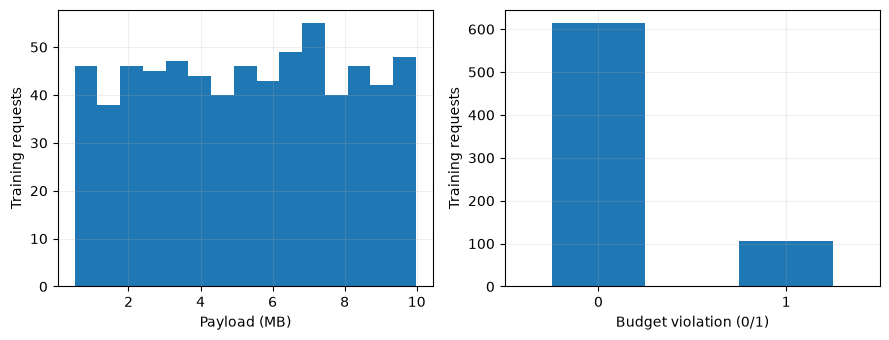

In [3]:
display(Xtr.head())
display(pd.DataFrame({'dtype': Xtr.dtypes.astype(str), 'missing': Xtr.isna().sum()}))
display(Xtr.describe(include='all'))
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
Xtr.payload.hist(ax=ax[0], bins=15); ax[0].set(xlabel='Payload (MB)', ylabel='Training requests')
ytr.value_counts().sort_index().plot.bar(ax=ax[1], rot=0)
ax[1].set(xlabel='Budget violation (0/1)', ylabel='Training requests')
plt.tight_layout(); plt.show()

## 2. Fit transformations on training rows
Numeric columns receive the training median, then training mean/SD scaling. Endpoint is
one-hot encoded: a separate 0/1 column for each training category. Numeric codes such as
`read=1, write=2` would imply a numerical geometry that these names do not have.

The fresh `preprocessing()` object has learned nothing. Fitting stores medians, scales, and
categories. Applying it to validation must leave all of those values unchanged.

In [4]:
prep = preprocessing()
Ztr = prep.fit_transform(Xtr)
scaler = prep.named_transformers_['numeric'].named_steps['standardscaler']
mean_before = scaler.mean_.copy()
Zva = prep.transform(Xva)
np.testing.assert_array_equal(mean_before, scaler.mean_)
assert np.isfinite(Ztr).all() and np.isfinite(Zva).all()
print('Raw training shape:', Xtr.shape, '| Prepared shape:', Ztr.shape)
display(pd.DataFrame(Ztr[:5], columns=prep.get_feature_names_out()))
unseen = Xva.iloc[:1].copy(); unseen['endpoint'] = 'batch'
print('Unknown category:', prep.transform(unseen)[0])

Raw training shape: (720, 4) | Prepared shape: (720, 5)


,numeric__payload,numeric__queue,numeric__cache,category__endpoint_read,category__endpoint_write
0,-1.259959,-0.571206,-0.821230,1.0,0.0
1,0.312192,-0.571206,-0.821230,0.0,1.0
2,-0.493425,-0.571206,1.217686,1.0,0.0
3,0.583615,-1.162960,-0.821230,0.0,1.0
4,0.933914,-1.162960,-0.821230,1.0,0.0


Unknown category: [-0.45876302  0.02054699 -0.82122993  0.          0.        ]


## 3. Establish what a trivial predictor achieves
The majority-class baseline learns only the most common training label. A high validation
accuracy can coexist with zero event recall. A baseline is a reference for the metric, not a
candidate to hide when it looks strong. This first session does not tune a classifier or open
the test set; later sessions reuse the protocol.

In [5]:
baseline = DummyClassifier(strategy='most_frequent').fit(Xtr, ytr)
prob = baseline.predict_proba(Xva)[:, 1]
display(pd.DataFrame([classification_report_row(yva, prob)], index=['validation majority baseline']))
print('Validation confusion matrix (rows actual, columns predicted):')
print(confusion_matrix(yva, baseline.predict(Xva), labels=[0, 1]))

,accuracy,precision,recall,F1,log_loss,FP,FN,cost_per_row
validation majority baseline,0.854167,0.0,0.0,0.0,5.256366,0,35,0.729167


Validation confusion matrix (rows actual, columns predicted):
[[205   0]
 [ 35   0]]


## 4. Diagnose a leakage mistake without executing it
```python
# WRONG: these transformations learn from every partition.
prepared = preprocessing().fit_transform(X)
# Splitting prepared afterward does not undo that information transfer.
```
A worse error would be including latency in `X`, since the target is defined from it.
An impressive score would then answer a different question: can we recover a known threshold?

**Discuss:** A new service has many `batch` requests. The encoder will run, but what evidence
supports its predictions? An all-zero category encoding avoids a software error; it does not
establish reliability on a new population.

## Closing exercise
Write a five-line experiment contract: unit of observation, prediction time, legal features,
target, and split strategy. Then explain why the baseline can be accurate yet operationally
unhelpful. Use the student application to audit an additional post-outcome field.

**Answer notes:** The observed latency and final status are unavailable at arrival. Zero is
not a missing payload. Training-only transformations preserve the held-out experiment.
Majority prediction ignores all positive events when the negative class is most frequent.
Next session turns a numerical prediction into an optimization problem.